    # Notebook 2 — Le modèle diagonal de Sharpe

    **Le Quotient Financier · Travaux pratiques d'histoire de la gestion de portefeuille**

    En 1963, William Sharpe propose une hypothèse simplificatrice : les titres ne sont liés entre eux
    qu'à travers le marché. Ce notebook l'applique aux dix titres du notebook 1.

    **Au programme**

    1. Estimer, pour chaque titre, l'alpha, le bêta et le risque propre par régression sur le marché.
    2. Construire la matrice de covariance de Sharpe et mesurer ce qu'elle perd.
    3. Programmer l'algorithme diagonal et vérifier qu'il donne le même résultat que Markowitz.
    4. Appliquer la règle de tri d'Elton, Gruber et Padberg (1976).
    5. Comparer les temps de calcul.
    6. Comparer la sensibilité aux erreurs d'estimation.
    7. Tester les stratégies hors échantillon, face au portefeuille équipondéré.

    **Prérequis** : le notebook 1, qui télécharge les données dans `donnees_prix.csv`.

> *Ce notebook est un support pédagogique du Quotient Financier. Il illustre des méthodes historiques
> et académiques ; il ne constitue en aucun cas un conseil en investissement ni une recommandation
> d'achat ou de vente de titres. Les titres utilisés servent uniquement d'exemples.*

## 0. Mise en place

In [19]:
# Sur Google Colab ou une installation neuve, décommentez la ligne suivante :
# !pip install yfinance numpy pandas scipy matplotlib

import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

import logging
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)   # masque les avertissements de polices
plt.rcParams.update({"figure.figsize": (9, 5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "mathtext.fontset": "dejavusans"})   # formules des axes (ex. 10^1) avec la police par défaut
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
np.set_printoptions(precision=4, suppress=True)

SEMAINES = 52              # nombre de semaines par an, pour annualiser
TAUX_SANS_RISQUE = 0.02    # taux sans risque annuel retenu (hypothèse simplificatrice)

In [20]:
# Dix titres américains, cinq secteurs, deux titres par secteur
TITRES = {
    "AAPL": "Technologie", "MSFT": "Technologie",
    "JPM": "Banque",       "BAC": "Banque",
    "XOM": "Énergie",      "CVX": "Énergie",
    "JNJ": "Santé",        "PFE": "Santé",
    "KO": "Consommation",  "PG": "Consommation",
}
MARCHE = "SPY"   # ETF S&P 500, utilisé comme indice de marché
ETF_SECTEURS = {"XLK": "Technologie", "XLF": "Banque", "XLE": "Énergie",
                "XLV": "Santé", "XLP": "Consommation"}

SECTEURS = {**TITRES, **ETF_SECTEURS, MARCHE: "Marché"}
TOUS = list(TITRES) + [MARCHE] + list(ETF_SECTEURS)
DEBUT, FIN = "2015-01-01", "2024-12-31"
FICHIER = "donnees_prix.csv"

In [21]:
def donnees_simulees(tickers, secteurs, debut, fin, graine=42):
    """Prix hebdomadaires simulés par un modèle à facteurs (marché + secteurs + bruit à queues épaisses).
    Utilisés uniquement si le téléchargement échoue, pour que le notebook reste exécutable."""
    rng = np.random.default_rng(graine)
    dates = pd.date_range(debut, fin, freq="W-FRI")
    T = len(dates)
    t5 = lambda: rng.standard_t(5, T) / np.sqrt(5 / 3)          # loi de Student, variance 1
    marche = 0.0025 + 0.022 * t5()
    facteurs = {s: 0.015 * t5() for s in set(secteurs.values())}
    rend = {}
    for t in tickers:
        s = secteurs.get(t, "Marché")
        if t == "SPY":
            r = marche + 0.001 * rng.standard_normal(T)
        elif t == "AGG":
            r = 0.0006 + 0.008 * rng.standard_normal(T) - 0.05 * marche
        elif t.startswith("XL"):
            r = rng.uniform(0.8, 1.2) * marche + facteurs[s] + 0.003 * rng.standard_normal(T)
        else:
            r = (0.0006 * rng.standard_normal() + rng.uniform(0.6, 1.4) * marche
                 + rng.uniform(0.8, 1.5) * facteurs[s] + 0.018 * t5())
        rend[t] = r
    return 100 * (1 + pd.DataFrame(rend, index=dates)).cumprod()


def charger_prix(tickers, secteurs, debut, fin, fichier):
    """Lit le fichier local s'il existe, sinon télécharge sur Yahoo Finance,
    sinon (pas d'accès internet) bascule sur des données simulées."""
    if os.path.exists(fichier):
        prix = pd.read_csv(fichier, index_col=0, parse_dates=True)
        if set(tickers) <= set(prix.columns):
            print(f"Données lues dans {fichier}.")
            return prix[tickers], "fichier local"
    try:
        import yfinance as yf
        prix = yf.download(tickers, start=debut, end=fin, auto_adjust=True, progress=False)["Close"]
        if prix is None or len(prix) == 0 or prix.dropna(how="all").empty:
            raise ValueError("aucune donnée reçue")
        prix = prix[tickers].dropna(how="all")
        manquants = [t for t in tickers if prix[t].isna().mean() > 0.05]
        if prix.empty or manquants:
            raise ValueError(f"séries incomplètes : {manquants}")
        prix.to_csv(fichier)
        print(f"Données téléchargées sur Yahoo Finance et enregistrées dans {fichier}.")
        return prix, "Yahoo Finance"
    except Exception as e:
        print("⚠️  Téléchargement impossible (" + str(e)[:90] + ").")
        print("⚠️  LE NOTEBOOK UTILISE DES DONNÉES SIMULÉES : les chiffres ne décrivent pas les vrais titres.")
        return donnees_simulees(tickers, secteurs, debut, fin), "simulées"


def rendements_hebdo(prix):
    """Rendements hebdomadaires simples, calculés sur les cours du vendredi."""
    return prix.resample("W-FRI").last().pct_change(fill_method=None).dropna(how="any")


def boites(ax, donnees, noms):
    """Boîtes à moustaches, une par colonne de `donnees` (compatible avec toutes les versions de matplotlib)."""
    ax.boxplot(np.asarray(donnees), showfliers=False)
    ax.set_xticks(range(1, len(noms) + 1))
    ax.set_xticklabels(list(noms), rotation=90)


def afficher_matrice(M, titre, vmin=-1, vmax=1, cmap="RdBu_r", fmt="{:.2f}"):
    """Affiche une matrice (DataFrame carré) sous forme de carte de chaleur annotée."""
    fig, ax = plt.subplots(figsize=(7, 6))
    im = ax.imshow(M.values, vmin=vmin, vmax=vmax, cmap=cmap)
    ax.set_xticks(range(len(M))); ax.set_xticklabels(M.columns, rotation=90)
    ax.set_yticks(range(len(M))); ax.set_yticklabels(M.index)
    for i in range(len(M)):
        for j in range(len(M)):
            ax.text(j, i, fmt.format(M.values[i, j]), ha="center", va="center", fontsize=7)
    ax.grid(False); ax.set_title(titre)
    fig.colorbar(im, ax=ax, shrink=0.8)
    plt.show()

In [22]:
# Outils d'optimisation (repris du notebook 1)
def tangent(Sigma_, mu_, rf=TAUX_SANS_RISQUE):
    """Portefeuille tangent, vente à découvert permise (formule fermée)."""
    x = np.linalg.solve(Sigma_, mu_ - rf)
    return x / x.sum()

def tangent_positif(Sigma_, mu_, rf=TAUX_SANS_RISQUE):
    """Portefeuille tangent à poids positifs (optimisation numérique)."""
    n = len(mu_)
    res = minimize(lambda w: -(w @ mu_ - rf) / np.sqrt(w @ Sigma_ @ w), np.ones(n) / n,
                   constraints=[{"type": "eq", "fun": lambda w: w.sum() - 1}],
                   bounds=[(0, 1)] * n, method="SLSQP", options={"ftol": 1e-10, "maxiter": 500})
    return res.x

def variance_min(Sigma_):
    """Portefeuille de variance minimale, vente à découvert permise."""
    x = np.linalg.solve(Sigma_, np.ones(len(Sigma_)))
    return x / x.sum()

def variance_min_positive(Sigma_):
    """Portefeuille de variance minimale à poids positifs."""
    n = len(Sigma_)
    res = minimize(lambda w: w @ Sigma_ @ w, np.ones(n) / n, jac=lambda w: 2 * Sigma_ @ w,
                   constraints=[{"type": "eq", "fun": lambda w: w.sum() - 1}],
                   bounds=[(0, 1)] * n, method="SLSQP", options={"ftol": 1e-12, "maxiter": 500})
    return res.x

def performance(r, rf=TAUX_SANS_RISQUE):
    """Indicateurs annualisés d'une série de rendements hebdomadaires."""
    valeur = (1 + r).cumprod()
    return pd.Series({"Rendement annuel": r.mean() * SEMAINES,
                      "Volatilité": r.std() * np.sqrt(SEMAINES),
                      "Ratio de Sharpe": (r.mean() * SEMAINES - rf) / (r.std() * np.sqrt(SEMAINES)),
                      "Perte maximale": (valeur / valeur.cummax() - 1).min()})

In [23]:
prix, SOURCE = charger_prix(TOUS, SECTEURS, DEBUT, FIN, FICHIER)
rendements = rendements_hebdo(prix)
rend = rendements[list(TITRES)].loc["2020":"2024"]
rm = rendements[MARCHE].loc["2020":"2024"]
N, T = rend.shape[1], rend.shape[0]

mu = rend.mean() * SEMAINES
Sigma = rend.cov() * SEMAINES
vol = np.sqrt(np.diag(Sigma))
print(f"Source : {SOURCE} — {N} titres, {T} semaines (2020-2024), marché : {MARCHE}")

Données lues dans donnees_prix.csv.
Source : fichier local — 10 titres, 261 semaines (2020-2024), marché : SPY


## 1. Alpha, bêta et risque propre

Sharpe écrit le rendement de chaque titre comme une fonction linéaire du rendement du marché $I$ :

$$R_i = a_i + b_i\, I + e_i, \qquad \mathbb{E}[e_i] = 0, \quad \operatorname{Cov}(e_i, I) = 0,
\quad \operatorname{Cov}(e_i, e_j) = 0 \;\; (i \neq j)$$

Les deux premières hypothèses sont automatiquement satisfaites par une régression par moindres carrés.
**La troisième est le vrai pari** : deux titres ne se parlent qu'à travers le marché.

L'estimateur des moindres carrés du bêta est :

$$\hat b_i = \frac{\widehat{\operatorname{Cov}}(R_i, I)}{\widehat{\operatorname{Var}}(I)}, \qquad
\hat a_i = \bar R_i - \hat b_i\, \bar I$$

### Exercice 1.1
Calculez le bêta et l'alpha de JPMorgan avec ces deux formules.

In [24]:
beta_jpm = rend["JPM"].cov(rm) / rm.var()
alpha_jpm = rend["JPM"].mean() - beta_jpm * rm.mean()
print(f"JPM : bêta = {beta_jpm:.3f}, alpha = {alpha_jpm * SEMAINES:+.2%} par an")

JPM : bêta = 1.097, alpha = +1.33% par an


### La régression complète, avec les erreurs-types

On généralise à tous les titres, en calculant aussi les statistiques $t$ (coefficient divisé par son erreur-type),
le $R^2$ (part de la variance expliquée par le marché) et la volatilité résiduelle.
Une statistique $t$ supérieure à 2 en valeur absolue signale un coefficient significativement différent de zéro.

In [25]:
def regression_marche(r_i, r_m):
    """Moindres carrés de r_i sur une constante et r_m. Renvoie alpha, bêta, résidus et erreurs-types."""
    X = np.column_stack([np.ones(len(r_m)), r_m])
    coef, *_ = np.linalg.lstsq(X, r_i, rcond=None)
    resid = r_i - X @ coef
    s2 = resid @ resid / (len(r_m) - 2)
    et = np.sqrt(np.diag(s2 * np.linalg.inv(X.T @ X)))
    return coef[0], coef[1], resid, et

lignes, residus = {}, {}
for t in TITRES:
    a_, b_, e_, et_ = regression_marche(rend[t].values, rm.values)
    residus[t] = e_
    lignes[t] = {"Secteur": TITRES[t], "Alpha annuel": a_ * SEMAINES, "t (alpha)": a_ / et_[0],
                 "Bêta": b_, "t (bêta)": b_ / et_[1],
                 "R²": 1 - e_.var() / rend[t].var(ddof=0),
                 "Volatilité propre": e_.std(ddof=1) * np.sqrt(SEMAINES)}
reg = pd.DataFrame(lignes).T
residus = pd.DataFrame(residus, index=rend.index)
reg

,Secteur,Alpha annuel,t (alpha),Bêta,t (bêta),R²,Volatilité propre
AAPL,Technologie,0.1306,1.5144,1.0741,18.0475,0.5570,0.1917
MSFT,Technologie,0.0896,1.1365,0.9664,17.7643,0.5492,0.1752
JPM,Banque,0.0133,0.1373,1.0971,16.3961,0.5093,0.2155
BAC,Banque,-0.0608,-0.5396,1.2189,15.6677,0.4866,0.2506
XOM,Énergie,0.0612,0.4506,0.8304,8.8610,0.2326,0.3019
CVX,Énergie,-0.0098,-0.0773,0.9489,10.8775,0.3136,0.2810
JNJ,Santé,-0.0261,-0.3620,0.4423,8.8871,0.2337,0.1603
PFE,Santé,-0.0740,-0.6924,0.5271,7.1490,0.1648,0.2375
KO,Consommation,-0.0373,-0.4965,0.7512,14.5097,0.4484,0.1668
PG,Consommation,0.0171,0.2436,0.5380,11.1072,0.3226,0.1560


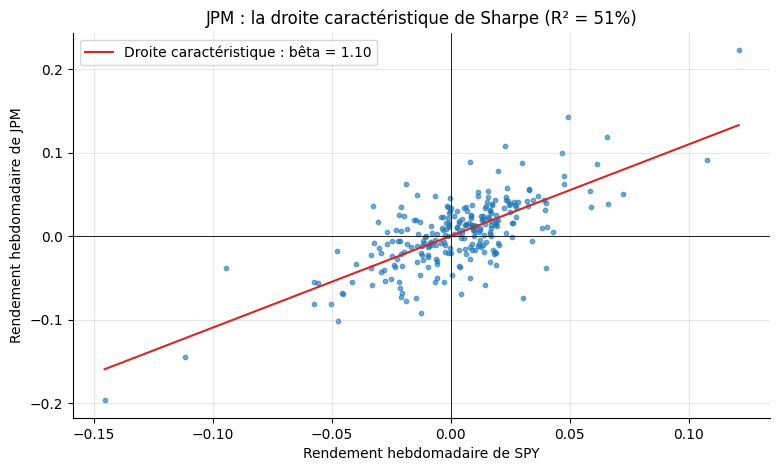

In [26]:
t = "JPM"
plt.scatter(rm, rend[t], s=10, alpha=0.6)
x = np.linspace(rm.min(), rm.max(), 10)
a_w, b_w = reg.loc[t, "Alpha annuel"] / SEMAINES, reg.loc[t, "Bêta"]
plt.plot(x, a_w + b_w * x, color="C3", label=f"Droite caractéristique : bêta = {b_w:.2f}")
plt.axhline(0, color="black", lw=0.6); plt.axvline(0, color="black", lw=0.6)
plt.xlabel(f"Rendement hebdomadaire de {MARCHE}"); plt.ylabel(f"Rendement hebdomadaire de {t}")
plt.title(f"{t} : la droite caractéristique de Sharpe (R² = {reg.loc[t, 'R²']:.0%})"); plt.legend(); plt.show()

### Question 1.2
Quels titres sont les plus sensibles au marché ? Combien d'alphas sont significatifs ?
Quelle part du risque de chaque titre vient du marché ?

> **Corrigé — commentaire.** Les bêtas sont presque tous très significatifs : le marché explique une part importante des fluctuations.
> Les alphas, en revanche, sont rarement significatifs : sur cinq ans, on ne distingue pas un vrai
> surplus de rendement du bruit. Le R² est la part du risque d'origine marché ; le reste, le risque propre,
> peut en principe être éliminé par la diversification. L'interprétation de l'alpha et du bêta
> est développée dans le notebook 4, consacré au CAPM.

## 2. La matrice de covariance de Sharpe

Avec ces hypothèses, toute la matrice se fabrique à partir de trois briques : les bêtas $b$, la variance du marché
$\sigma_I^2$ et la matrice diagonale $D$ des variances résiduelles.

$$\Sigma_{\text{Sharpe}} = \sigma_I^2\, b\, b^\top + D, \qquad
\sigma_{ij} = b_i\, b_j\, \sigma_I^2 \;\; (i \neq j), \qquad \sigma_i^2 = b_i^2 \sigma_I^2 + \sigma_{e_i}^2$$

### Exercice 2.1
Construisez `Sigma_sharpe` (annualisée) et vérifiez que sa diagonale coïncide avec celle de la matrice empirique.

In [27]:
b = reg["Bêta"].values.astype(float)
var_m = rm.var() * SEMAINES
var_e = residus.var(ddof=1).values * SEMAINES
Sigma_sharpe = var_m * np.outer(b, b) + np.diag(var_e)

print("Écart maximal sur la diagonale :", np.abs(np.diag(Sigma_sharpe) - np.diag(Sigma.values)).max())

Écart maximal sur la diagonale : 5.551115123125783e-17


> **Corrigé — commentaire.** La diagonale est identique : la régression décompose exactement chaque variance en une part marché
> et une part propre. Le modèle ne se trompe donc que sur les covariances, en dehors de la diagonale.

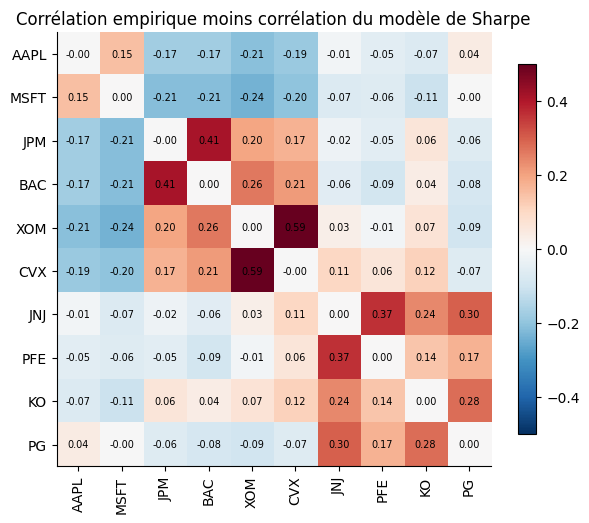

,Empirique,Modèle de Sharpe
AAPL / MSFT,0.7043,0.5531
JPM / BAC,0.9089,0.4978
XOM / CVX,0.8611,0.2701
JNJ / PFE,0.5619,0.1962
KO / PG,0.6590,0.3804
AAPL / XOM,0.1508,0.3600


In [28]:
sd = np.sqrt(np.diag(Sigma_sharpe))
corr_sharpe = pd.DataFrame(Sigma_sharpe / np.outer(sd, sd), index=TITRES, columns=TITRES)
corr_emp = rend.corr()
afficher_matrice(corr_emp - corr_sharpe, "Corrélation empirique moins corrélation du modèle de Sharpe",
                 vmin=-0.5, vmax=0.5)

paires = [("AAPL", "MSFT"), ("JPM", "BAC"), ("XOM", "CVX"), ("JNJ", "PFE"), ("KO", "PG"), ("AAPL", "XOM")]
pd.DataFrame({"Empirique": [corr_emp.loc[p] for p in paires],
              "Modèle de Sharpe": [corr_sharpe.loc[p] for p in paires]},
             index=[f"{a} / {b_}" for a, b_ in paires])

> **Corrigé — commentaire.** Le modèle sous-estime systématiquement les corrélations à l'intérieur d'un même secteur (les cases rouges
> sur la diagonale par blocs) : le lien entre deux banques ou deux pétrolières ne passe pas seulement par le marché.
> C'est le biais du modèle. Entre secteurs différents, l'approximation est en général bonne.

## 3. L'algorithme diagonal

Sharpe traite l'indice comme un titre de plus, de poids $w_{N+1} = \sum_i b_i w_i$, le bêta du portefeuille.
Le portefeuille se décompose alors en $N+1$ morceaux indépendants, et la variance perd ses termes croisés :

$$\sigma_p^2 = \sum_{i=1}^{N} w_i^2\, \sigma_{e_i}^2 + w_{N+1}^2\, \sigma_I^2 = \tilde w^\top \tilde D\, \tilde w,
\qquad \tilde D = \operatorname{diag}(\sigma_{e_1}^2, \dots, \sigma_{e_N}^2, \sigma_I^2)$$

Le rendement espéré s'écrit $\sum_i w_i a_i + w_{N+1}\,\mu_I$. Le problème devient :

$$\min_{\tilde w}\; \tfrac{1}{2}\,\tilde w^\top \tilde D\, \tilde w \quad \text{sous} \quad
\underbrace{\begin{pmatrix} a_1 & \cdots & a_N & \mu_I \\ 1 & \cdots & 1 & 0 \\ b_1 & \cdots & b_N & -1 \end{pmatrix}}_{\mathbf{A}}
\tilde w = \begin{pmatrix} m \\ 1 \\ 0 \end{pmatrix}$$

La solution s'écrit $\tilde w = \tilde D^{-1} \mathbf{A}^\top \nu$ avec $\nu = (\mathbf{A}\tilde D^{-1}\mathbf{A}^\top)^{-1} c$.
Inverser $\tilde D$ revient à diviser par chaque terme de la diagonale, et la seule vraie inversion porte
sur une matrice **3 × 3**, quel que soit le nombre de titres.

### Exercice 3.1
Programmez l'algorithme et vérifiez qu'il donne exactement le même portefeuille que la formule fermée de Markowitz
appliquée à `Sigma_sharpe`.

In [29]:
mu_m = rm.mean() * SEMAINES
a = mu.values - b * mu_m                       # constantes a_i, en annualisé
d = np.append(var_e, var_m)                    # diagonale de D tilde
A_cons = np.vstack([np.append(a, mu_m),        # rendement
                    np.append(np.ones(N), 0),  # budget (l'indice fictif n'en fait pas partie)
                    np.append(b, -1)])         # lien : w_{N+1} = somme des b_i w_i

def diagonal_cible(m):
    c = np.array([m, 1.0, 0.0])
    M = A_cons @ (A_cons.T / d[:, None])       # matrice 3 x 3
    nu = np.linalg.solve(M, c)
    return (A_cons.T @ nu) / d                 # vecteur de N + 1 poids

def markowitz_cible(Sigma_, mu_, m):
    Si_ = np.linalg.inv(Sigma_); un_ = np.ones(len(mu_))
    A_, B_, C_ = un_ @ Si_ @ un_, un_ @ Si_ @ mu_, mu_ @ Si_ @ mu_
    D_ = A_ * C_ - B_**2
    return Si_ @ ((A_ * m - B_) / D_ * mu_ + (C_ - B_ * m) / D_ * un_)

m_test = 0.12
w_diag = diagonal_cible(m_test)
w_mark = markowitz_cible(Sigma_sharpe, mu.values, m_test)
print("Écart maximal entre les deux méthodes :", np.abs(w_diag[:N] - w_mark).max())
print(f"Poids de l'indice fictif : {w_diag[N]:.4f} — bêta du portefeuille : {b @ w_diag[:N]:.4f}")

Écart maximal entre les deux méthodes : 5.551115123125783e-16
Poids de l'indice fictif : 0.5872 — bêta du portefeuille : 0.5872


> **Corrigé — commentaire.** Les deux méthodes coïncident à la précision de la machine : l'astuce diagonale ne change pas le résultat,
> seulement la façon de le calculer. Et le poids de l'indice fictif est bien égal au bêta du portefeuille.

### 3.2 Sherman-Morrison : l'inverse en une ligne

Une matrice « diagonale plus rang un » s'inverse explicitement :

$$\Sigma_{\text{Sharpe}}^{-1} = D^{-1} - \frac{D^{-1} b\, b^\top D^{-1}}{\sigma_I^{-2} + b^\top D^{-1} b}$$

Pour calculer $\Sigma^{-1}v$, il suffit donc de quelques produits de vecteurs : le coût est proportionnel à $N$,
et non plus à $N^3$.

In [30]:
def sharpe_resoudre(b_, var_e_, var_m_, v):
    """Calcule Sigma_Sharpe^{-1} v sans jamais former ni inverser la matrice (Sherman-Morrison)."""
    x = v / var_e_
    return x - (b_ / var_e_) * (b_ @ x) / (1 / var_m_ + b_ @ (b_ / var_e_))

v = mu.values - TAUX_SANS_RISQUE
print("Écart avec l'inversion directe :",
      np.abs(sharpe_resoudre(b, var_e, var_m, v) - np.linalg.solve(Sigma_sharpe, v)).max())

Écart avec l'inversion directe : 1.3322676295501878e-15


### 3.3 La règle de tri d'Elton, Gruber et Padberg (1976)

Dans le modèle de Sharpe, le portefeuille tangent **sans vente à découvert** se calcule sans optimiseur :

1. Classer les titres par **ratio de Treynor** décroissant, $(\mu_i - r_f)/b_i$.
2. Pour chaque rang $k$, calculer le seuil
   $C_k = \dfrac{\sigma_I^2 \sum_{j \le k} (\mu_j - r_f) b_j / \sigma_{e_j}^2}{1 + \sigma_I^2 \sum_{j \le k} b_j^2 / \sigma_{e_j}^2}$.
3. Retenir les titres dont le ratio de Treynor dépasse leur seuil ; le dernier seuil retenu est $C^*$.
4. Poids proportionnels à $z_i = \dfrac{b_i}{\sigma_{e_i}^2}\left(\dfrac{\mu_i - r_f}{b_i} - C^*\right)$.

### Exercice 3.3
Programmez la règle et comparez le résultat au portefeuille tangent à poids positifs obtenu par optimisation
numérique avec `Sigma_sharpe`.

In [31]:
def egp(mu_, b_, var_e_, var_m_, rf=TAUX_SANS_RISQUE):
    """Portefeuille tangent sans vente à découvert dans le modèle de Sharpe (Elton, Gruber, Padberg 1976).
    Suppose des bêtas positifs."""
    exces = mu_ - rf
    treynor = exces / b_
    ordre = np.argsort(-treynor)
    num = np.cumsum((exces * b_ / var_e_)[ordre])
    den = np.cumsum((b_**2 / var_e_)[ordre])
    seuils = var_m_ * num / (1 + var_m_ * den)
    retenus = np.where(treynor[ordre] > seuils)[0]
    if len(retenus) == 0:
        return None
    k = retenus.max()
    c_star = seuils[k]
    z = np.zeros(len(mu_))
    sel = ordre[:k + 1]
    z[sel] = b_[sel] / var_e_[sel] * (treynor[sel] - c_star)
    return np.clip(z, 0, None) / np.clip(z, 0, None).sum()

w_egp = egp(mu.values, b, var_e, var_m)
w_num = tangent_positif(Sigma_sharpe, mu.values)
pd.DataFrame({"Ratio de Treynor": (mu.values - TAUX_SANS_RISQUE) / b,
              "Règle de tri (EGP)": w_egp, "Optimiseur numérique": w_num}, index=TITRES
             ).sort_values("Ratio de Treynor", ascending=False).style.format(
                 {"Ratio de Treynor": "{:.3f}", "Règle de tri (EGP)": "{:.1%}", "Optimiseur numérique": "{:.1%}"})

,Ratio de Treynor,Règle de tri (EGP),Optimiseur numérique
AAPL,0.260,56.0%,56.0%
MSFT,0.229,37.8%,37.8%
XOM,0.207,6.2%,6.2%
PG,0.152,0.0%,0.0%
JPM,0.151,0.0%,0.0%
CVX,0.126,0.0%,0.0%
BAC,0.091,0.0%,0.0%
KO,0.081,0.0%,0.0%
JNJ,0.053,0.0%,0.0%
PFE,-0.021,0.0%,0.0%


> **Corrigé — commentaire.** La règle de tri retrouve le résultat de l'optimiseur, à de petites différences numériques près.
> L'optimisation de portefeuille devient un simple classement : on pourrait la faire avec un crayon.

## 4. Le gain de temps

Comparons le calcul du portefeuille tangent avec la matrice pleine (formation de la matrice puis résolution d'un
système $N \times N$) et avec Sherman-Morrison (opérations sur des vecteurs). On fabrique pour cela des
univers fictifs de grande taille.

In [32]:
def chrono(f, repetitions=3):
    t0 = time.perf_counter()
    for _ in range(repetitions):
        f()
    return (time.perf_counter() - t0) / repetitions

rng = np.random.default_rng(3)
lignes = []
for n in (100, 500, 1000, 2000, 4000, 100_000, 1_000_000):
    b_n = rng.normal(1, 0.25, n); ve_n = rng.uniform(0.02, 0.09, n); mu_n = rng.uniform(0.04, 0.12, n)
    t_diag = chrono(lambda: sharpe_resoudre(b_n, ve_n, 0.03, mu_n - TAUX_SANS_RISQUE))
    if n <= 4000:
        t_plein = chrono(lambda: np.linalg.solve(0.03 * np.outer(b_n, b_n) + np.diag(ve_n), mu_n - TAUX_SANS_RISQUE))
    else:
        t_plein = np.nan
    lignes.append({"Titres": n, "Paramètres (Markowitz)": 2 * n + n * (n - 1) // 2,
                   "Paramètres (Sharpe)": 3 * n + 2,
                   "Matrice pleine (ms)": 1000 * t_plein, "Modèle diagonal (ms)": 1000 * t_diag})
pd.DataFrame(lignes).set_index("Titres").style.format(
    {"Paramètres (Markowitz)": "{:,.0f}", "Paramètres (Sharpe)": "{:,.0f}",
     "Matrice pleine (ms)": "{:.2f}", "Modèle diagonal (ms)": "{:.3f}"}, na_rep="(mémoire insuffisante)")

,Paramètres (Markowitz),Paramètres (Sharpe),Matrice pleine (ms),Modèle diagonal (ms)
Titres,,,,
100,"5,150",302,35.69,0.054
500,"125,750","1,502",141.42,0.062
1000,"501,500","3,002",208.66,0.053
2000,"2,003,000","6,002",965.89,0.067
4000,"8,006,000","12,002",5655.77,0.234
100000,"5,000,150,000","300,002",(mémoire insuffisante),6.571
1000000,"500,001,500,000","3,000,002",(mémoire insuffisante),134.373


> **Corrigé — commentaire.** Avec le modèle diagonal, un univers d'un million de titres se traite en quelques millisecondes,
> alors que la matrice pleine occuperait à elle seule 8 téraoctets de mémoire. En 1963, ce gain
> faisait passer le calcul de 100 titres de 33 minutes à 30 secondes sur IBM 7090.

## 5. Moins de sensibilité aux erreurs

Reprenons l'expérience du notebook 1 : un point de rendement espéré en plus sur JPMorgan.

### Exercice 5.1
Calculez le portefeuille tangent (vente à découvert permise) avant et après le choc, avec la matrice empirique
puis avec la matrice de Sharpe. Comparez aussi les **nombres de conditionnement** des deux matrices
(rapport entre la plus grande et la plus petite valeur propre) : plus il est élevé, plus l'inversion amplifie les erreurs.

In [33]:
mu_choc = mu.copy(); mu_choc["JPM"] += 0.01
res = {}
for nom, S_ in (("Markowitz (empirique)", Sigma.values), ("Sharpe (diagonal)", Sigma_sharpe)):
    avant, apres = tangent(S_, mu.values), tangent(S_, mu_choc.values)
    res[(nom, "Avant")] = avant
    res[(nom, "Après")] = apres
    print(f"{nom:<24} conditionnement = {np.linalg.cond(S_):6.1f}   "
          f"déplacement total des poids = {np.abs(apres - avant).sum():.0%}")
pd.DataFrame(res, index=TITRES).style.format("{:+.1%}")

Markowitz (empirique)    conditionnement =   44.8   déplacement total des poids = 29%
Sharpe (diagonal)        conditionnement =   14.6   déplacement total des poids = 23%


In [34]:
rng = np.random.default_rng(4)
et_mu = vol / np.sqrt(T / SEMAINES)
bruits = rng.normal(0, et_mu, (1000, N))
deplacement = {}
for nom, S_ in (("Markowitz (empirique)", Sigma.values), ("Sharpe (diagonal)", Sigma_sharpe)):
    gamma = np.linalg.solve(S_, mu.values - TAUX_SANS_RISQUE).sum()   # aversion au risque fixe (notebook 1)
    deplacement[nom] = [np.abs(np.linalg.solve(S_, e)).sum() / abs(gamma) for e in bruits]
deplacement = pd.DataFrame(deplacement)
print("Déplacement médian des poids (aversion au risque fixe) face à des erreurs plausibles sur les rendements :")
print(deplacement.median().map("{:.0%}".format).to_string())

Déplacement médian des poids (aversion au risque fixe) face à des erreurs plausibles sur les rendements :
Markowitz (empirique)    1235%
Sharpe (diagonal)        1180%


> **Corrigé — commentaire.** La matrice de Sharpe est mieux conditionnée : elle amplifie moins les erreurs. En particulier, elle ne voit pas
> JPM et BAC comme des jumelles parfaites, et l'optimiseur est moins tenté de les arbitrer l'une contre l'autre.
> Le biais du modèle le protège. Mais l'amélioration reste partielle : l'essentiel de l'instabilité vient
> des rendements espérés, que le modèle de Sharpe ne corrige pas.

## 6. L'épreuve hors échantillon

Une méthode d'estimation se juge sur des données qu'elle n'a pas vues. On simule une gestion réaliste :
toutes les 4 semaines, on estime les paramètres sur les 3 années précédentes, on calcule les poids
(sans vente à découvert), puis on mesure le rendement obtenu les 4 semaines suivantes.

Cinq stratégies sont comparées :

- **1/N** : le portefeuille équipondéré, qui n'estime rien ;
- **Variance minimale**, avec la matrice empirique puis avec la matrice de Sharpe : elles n'utilisent pas les rendements espérés ;
- **Tangent**, avec la matrice empirique (optimiseur) puis avec le modèle de Sharpe (règle de tri) : elles utilisent la moyenne historique.

Simplification : entre deux dates, on suppose que les poids sont maintenus constants chaque semaine.

In [35]:
FENETRE, PAS = 156, 4
R, RM = rendements[list(TITRES)], rendements[MARCHE]

def parametres_sharpe(hist, hm):
    """Bêtas, variances résiduelles et variance du marché (annualisées), puis matrice de Sharpe."""
    X = np.column_stack([np.ones(len(hm)), hm.values])
    coef, *_ = np.linalg.lstsq(X, hist.values, rcond=None)
    bb = coef[1]
    ve = (hist.values - X @ coef).var(axis=0, ddof=1) * SEMAINES
    vm = hm.var() * SEMAINES
    return bb, ve, vm, vm * np.outer(bb, bb) + np.diag(ve)

strategies = ["1/N", "Variance min. — empirique", "Variance min. — Sharpe",
              "Tangent — empirique", "Tangent — Sharpe (règle de tri)"]
rend_strat = {s: [] for s in strategies}
rotation = {s: [] for s in strategies}
precedents = {s: np.ones(N) / N for s in strategies}
dates = []

for k in range(FENETRE, len(R) - 1, PAS):
    hist, hm = R.iloc[k - FENETRE:k], RM.iloc[k - FENETRE:k]
    mu_h, S_h = hist.mean().values * SEMAINES, hist.cov().values * SEMAINES
    bb, ve, vm, S_sh = parametres_sharpe(hist, hm)
    poids = {"1/N": np.ones(N) / N,
             "Variance min. — empirique": variance_min_positive(S_h),
             "Variance min. — Sharpe": variance_min_positive(S_sh)}
    if (mu_h - TAUX_SANS_RISQUE).max() > 0:
        poids["Tangent — empirique"] = tangent_positif(S_h, mu_h)
        w_e = egp(mu_h, bb, ve, vm) if (bb > 0).all() else None
        poids["Tangent — Sharpe (règle de tri)"] = w_e if w_e is not None else variance_min_positive(S_sh)
    else:   # aucun titre ne bat le taux sans risque : on se replie sur la variance minimale
        poids["Tangent — empirique"] = poids["Variance min. — empirique"]
        poids["Tangent — Sharpe (règle de tri)"] = poids["Variance min. — Sharpe"]
    futur = R.iloc[k:k + PAS]
    dates.extend(futur.index)
    for s in strategies:
        rend_strat[s].extend(futur.values @ poids[s])
        rotation[s].append(np.abs(poids[s] - precedents[s]).sum())
        precedents[s] = poids[s]

rend_strat = pd.DataFrame(rend_strat, index=dates)
bilan = rend_strat.apply(performance).T
bilan["Rotation moyenne"] = pd.Series({s: np.mean(rotation[s][1:]) for s in strategies})
print(f"Période de test : {rend_strat.index[0]:%m/%Y} à {rend_strat.index[-1]:%m/%Y}")
bilan.style.format({"Rendement annuel": "{:.1%}", "Volatilité": "{:.1%}", "Ratio de Sharpe": "{:.2f}",
                    "Perte maximale": "{:.1%}", "Rotation moyenne": "{:.0%}"})

Période de test : 01/2018 à 01/2025


,Rendement annuel,Volatilité,Ratio de Sharpe,Perte maximale,Rotation moyenne
1/N,14.3%,17.8%,0.69,-33.1%,0%
Variance min. — empirique,8.7%,16.6%,0.40,-32.6%,10%
Variance min. — Sharpe,6.6%,16.4%,0.28,-28.9%,5%
Tangent — empirique,16.7%,21.1%,0.70,-29.9%,25%
Tangent — Sharpe (règle de tri),14.8%,21.7%,0.59,-28.9%,25%


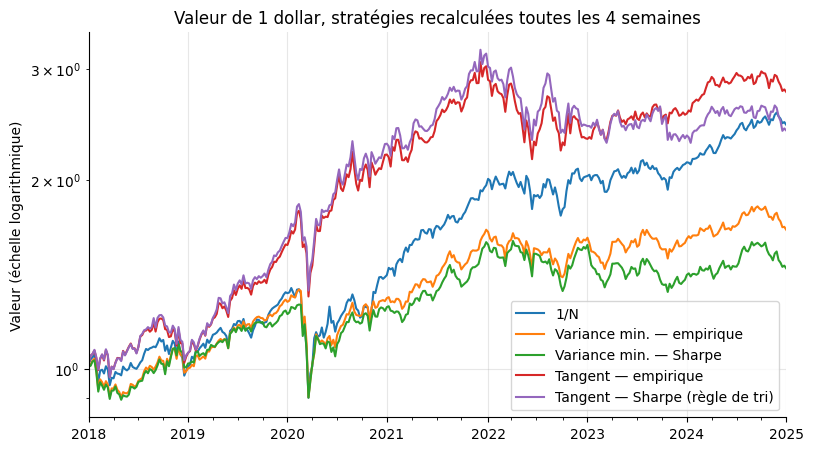

In [36]:
(1 + rend_strat).cumprod().plot(title="Valeur de 1 dollar, stratégies recalculées toutes les 4 semaines", logy=True)
plt.ylabel("Valeur (échelle logarithmique)"); plt.show()

### Question 6.1
Quelle stratégie a la volatilité la plus faible ? Le meilleur ratio de Sharpe ? La rotation la plus élevée ?
Les portefeuilles tangents, qui utilisent les rendements historiques, battent-ils le 1/N ?

> **Corrigé — commentaire.** Les résultats dépendent de la période et de ces dix titres : une seule histoire ne prouve rien.
> On retrouve néanmoins en général trois constats de la littérature. Les portefeuilles de variance minimale
> tiennent leur promesse de volatilité plus faible. Les portefeuilles tangents tournent beaucoup
> et peinent à battre le 1/N, comme l'ont montré DeMiguel, Garlappi et Uppal (2009). Et la version Sharpe
> est en général plus stable que la version empirique.

## 7. Bilan

| | Markowitz | Sharpe (1963) |
|---|---|---|
| Paramètres pour 1 000 titres | 501 500 | 3 002 |
| Inversion | matrice $N \times N$ | divisions + système $3 \times 3$ |
| Biais | aucun | sous-estime les corrélations sectorielles |
| Sensibilité aux erreurs | forte | atténuée, pas supprimée |

**Pour aller plus loin**

1. Remplacez `SPY` par l'ETF sectoriel de chaque titre comme indice. Les résidus sont-ils moins corrélés ?
2. Raccourcissez la fenêtre d'estimation à 1 an (52 semaines) dans la section 6. Quelle méthode souffre le plus ?
3. Dans la section 5, remplacez la moyenne historique par des rendements implicites $\mu_i = r_f + b_i\,(\mu_I - r_f)$.
   Que devient l'instabilité ?

**Suite** : *Notebook 3 — Les modèles multifactoriels*, qui corrige le biais sectoriel.